# RV, FWHM and asymmetry from a CCF template instead of a gaussian fit

The CCFs of a spot transit and a facula transit (MURaM spectra, same setup as the tutorial) are measured in four ways:

| method | what is fitted | outputs |
|---|---|---|
| **gaussian** (SunSim now) | gaussian + offset, `compute_ccf_params` | RV, FWHM, contrast, BIS |
| **A: linear projection** | C ≈ a T + b + c₁ T′ + c₂ T″ + c₃ T‴, one linear solve for all the epochs (Bouchy et al. 2001; dLW of SERVAL / LBL) | RV = −c₁/a, ΔFWHM from c₂, contrast a, asymmetry d3 from c₃ |
| **B: nonlinear template fit** | C(v) ≈ a T(v_c + (v − v_c − RV)/k) + b, least squares | RV, ΔFWHM = (k − 1) FWHM_T, contrast a |
| **C: FIESTA** (Zhao et al. 2022) | phase of each Fourier mode of C relative to T | one RV per mode, RV_k |

**The template T** is the disc-integrated CCF of the quiet photosphere: a simulation without any region (same star, same rings, same grids). It is noise-free and depends only on the star. All the quantities below are relative to it, so they are 0 for the quiet star.

Background and references: `ccf_template_matching.md` (project notes, Oct 20 2026).

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import time as timer
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
from scipy.optimize import least_squares

from sunsim import *
from sunsim import local_path

## 1. Star, spectra and CCF grids

As in sections 2.4 and 7 of the tutorial: MURaM high resolution spectra of the quiet photosphere and of the faculae (200 G), the spot spectrum is the quiet one (vx-drift corrected SSD) times the black-body ratio for ΔT = 500 K, HARPS G2 mask, 30 rings, the Dumusque bisector added to the spot only. One rotation with 121 epochs; the regions are on the equator at longitude 180°, so they cross the centre of the disc at t = P/2 and none is visible at t = 0.

In [2]:
rotation_period = 24.47            # [days]
inclination = 0                    # [rad] equator-on
T_quiet = 5770                     # [K]
spot_dT = 500                      # [K]
N_rings = 30
time = np.linspace(0, rotation_period, 121)

flux_quiet = np.load(str(local_path('muram_spectra') / 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_fc = np.load(str(local_path('muram_spectra') / 'av_solar_faculae_200G_10_mu_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
flux_sp = np.load(str(local_path('muram_spot_spectra') / 'av_solar_ssd_10_mu_angles_angles_PHOENIX_high_res_grid.npy'), allow_pickle=True).item()
for mu in flux_sp:
    flux_sp[mu]['intensity'] *= black_body(flux_sp[mu]['wav'], T_quiet - spot_dT) / black_body(flux_sp[mu]['wav'], T_quiet)

wvm, fm = mask_weights(str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas'))
rv_grid = np.arange(-18000, 18025, 25)             # [m/s]

def make_ccf_grid(flux, cb, bisector):
    g = CCF_grid(N_rings, flux, rv_grid, wvm, fm, convective_blueshift=cb, phoenix_resolution=True, normalization=False)
    g.built_grid(bisector=bisector)
    return g

ccf_quiet = make_ccf_grid(flux_quiet, 0, None)
ccf_fac = make_ccf_grid(flux_fc, 0, None)
ccf_spot = make_ccf_grid(flux_sp, 1, dumusque_bisector(normalization=False))

## 2. Simulations and template

`quiet` has no region: its CCF is the template (the same at every epoch). The first epoch of `spot` and `facula` is the quiet star too (checked).

In [3]:
scenarios = {
    'quiet':  [],
    'spot':   [active_region('sp', 10, 90, 180)],
    'facula': [active_region('fc', 10, 90, 180)],
}
sims = {}
for name, regions in scenarios.items():
    ss = StarSim(time, N_rings, inclination=inclination, rotation_period=rotation_period,
                 differential_rotation=SOLAR_DIFFERENTIAL_ROTATION, active_regions_map=regions, mode=['ccf'],
                 stellar_radius=1, ccf_grid_qp=ccf_quiet, ccf_grid_sp=ccf_spot, ccf_grid_fc=ccf_fac)
    ss.generate_timeseries(verbose=False)
    sims[name] = ss

rv = sims['quiet'].ccf_rv
template = sims['quiet'].ccf_var[0]
fwhm_t = sims['quiet'].fwhm_var[0]            # FWHM of the template (gaussian fit) [m/s]
v_c = sims['quiet'].rv_var[0]                 # centre of the template (gaussian fit) [m/s]
for name in ('spot', 'facula'):
    assert np.allclose(sims[name].ccf_var[0], template, rtol=1e-12, atol=0), name
print('template: RV = %.1f m/s, FWHM = %.1f m/s, vsini = %.0f m/s' % (v_c, fwhm_t, sims['quiet'].vsini))

template: RV = -968.1 m/s, FWHM = 6989.7 m/s, vsini = 2069 m/s


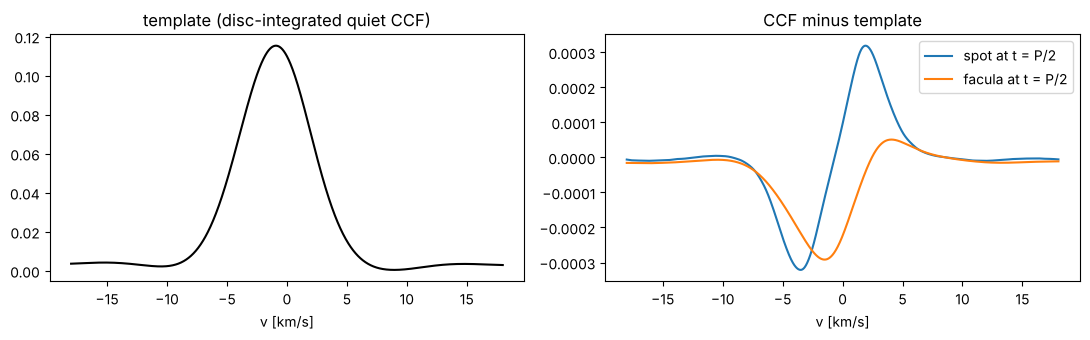

In [4]:
# SunSim CCFs are peaks (the inverted line): the template and the window where A and B are fitted
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(rv / 1e3, template, 'k')
ax[0].set_xlabel('v [km/s]'); ax[0].set_title('template (disc-integrated quiet CCF)')
k_c = np.argmin(np.abs(time - rotation_period / 2))
for name in ('spot', 'facula'):
    ax[1].plot(rv / 1e3, sims[name].ccf_var[k_c] - template, label='%s at t = P/2' % name)
ax[1].set_xlabel('v [km/s]'); ax[1].set_title('CCF minus template'); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. The three methods

**A** is linear: the design matrix is the same for every CCF, so all the epochs are one `lstsq`. T″ is orthogonalised against (T, 1, T′) and T‴ against (T, 1, T′, T″), so the RV is exactly the Bouchy projection (fit with T, 1, T′ only), and c₂ and c₃ only take what the previous terms cannot explain. ΔFWHM uses T ⊗ G(σ²) ≈ T + σ²/2 T″, exact for a gaussian; d3 = c₃/(a σ_T²) is in m/s. The projection is linear in the shift: `n_iter > 1` shifts the template by the RV found and projects again (needed for shifts of hundreds of m/s, see section 4).

**B** fits a shifted and stretched template (stretch k around its centre v_c, so it can be broader or narrower) with `scipy.optimize.least_squares`, epoch by epoch.

**C** uses the whole rv grid; the continuum (median of the 50 first and last points) is subtracted first. Only the first modes are used: their amplitude decreases fast (printed below), and the edges of the grid, where the CCF is not exactly flat, bias the higher ones (section 4).

In [5]:
LN2 = np.log(2.0)


def fit_window(rv, template, n_fwhm=1.5):
    """Indices of rv within n_fwhm FWHM of the peak of the template (peak-shaped CCF)."""
    base = np.median(np.r_[template[:50], template[-50:]])
    c = template - base
    k = np.argmax(c)
    half = c[k] / 2
    left = rv[:k][c[:k] < half][-1]
    right = rv[k:][c[k:] < half][0]
    fwhm = right - left
    centre = 0.5 * (left + right)
    return (rv > centre - n_fwhm * fwhm) & (rv < centre + n_fwhm * fwhm), fwhm


# ---------------------------------------------------------------- method A: linear projection on the derivatives
def _gram_schmidt(cols):
    """Each column orthogonalised against the previous ones (the coefficients of the previous ones then do not
    depend on the later columns)."""
    out = []
    for c in cols:
        v = c.astype(float).copy()
        for u in out:
            v -= (v @ u) / (u @ u) * u
        out.append(v)
    return out


def template_projection(rv, ccfs, template, window, fwhm_t, n_iter=1):
    """Method A. Every CCF C is fitted as a T + b + c1 T' + c2 T'' + c3 T''' on the window, with T'' orthogonalised
    against (T, 1, T') and T''' against (T, 1, T', T''). Then
      rv   = -c1/a                       (Bouchy et al. 2001; the same as the fit with T, 1, T' only)
      dfwhm = 8 ln2 (c2/a) / FWHM_T      (T convolved with a gaussian of variance s2 = T + s2/2 T'')
      d3   = c3/(a sigma_T^2)            [m/s], the odd part of the shape change that is not a shift (sigma_T = FWHM_T/2.355)
      a    = contrast relative to the template.
    n_iter > 1: the template is shifted by the RV found and the projection is redone (for shifts that are not small
    compared with the width of the CCF). All the CCFs are solved at once (one matrix for all the epochs)."""
    ccfs = np.atleast_2d(ccfs)
    sig_t = fwhm_t / np.sqrt(8 * LN2)
    rvs_tot = np.zeros(len(ccfs))
    for it in range(n_iter):
        out = {k: np.zeros(len(ccfs)) for k in ('rv', 'dfwhm', 'd3', 'a', 'b')}
        # one template per CCF only when it is shifted (iterations); else one design matrix for all of them
        shifts = np.unique(rvs_tot)
        for s in shifts:
            idx = np.where(rvs_tot == s)[0]
            spl = CubicSpline(rv + s, template)  # spl(v) = T(v - s): template shifted by s
            x = rv[window]
            T0, T1, T2, T3 = (spl(x, nu) for nu in range(4))
            cols = _gram_schmidt([T0, np.ones_like(x), T1, T2, T3])
            X = np.stack(cols, axis=1)
            coef, *_ = np.linalg.lstsq(X, ccfs[idx][:, window].T, rcond=None)
            a, b, c1, c2, c3 = coef
            out['rv'][idx] = s - c1 / a
            out['dfwhm'][idx] = 8 * LN2 * (c2 / a) / fwhm_t
            out['d3'][idx] = c3 / a / sig_t**2
            out['a'][idx] = a
            out['b'][idx] = b
        rvs_tot = out['rv'].copy()
    return out


# ---------------------------------------------------------------- method B: nonlinear fit of the template
def template_fit(rv, ccfs, template, window, fwhm_t, v_c):
    """Method B. Least-squares fit of C(v) = a T_c(v_c + (v - v_c - rv)/k) + a base + b on the window, where T_c is the
    template minus its continuum (base) and v_c its centre: shift rv, contrast a, offset b and stretch k of the velocity
    axis around v_c (k > 1 broader, k < 1 narrower). dfwhm = (k - 1) FWHM_T."""
    ccfs = np.atleast_2d(ccfs)
    base = np.median(np.r_[template[:50], template[-50:]])
    spl = CubicSpline(rv, template - base)
    x = rv[window]
    out = {k: np.zeros(len(ccfs)) for k in ('rv', 'dfwhm', 'a', 'b', 'k')}
    p = np.array([1.0, 0.0, 1.0, 0.0])
    for i, c in enumerate(ccfs):
        y = c[window]

        def resid(q):
            a, b, k, sh = q
            return a * spl(v_c + (x - v_c - sh) / k) + a * base + b - y

        p = least_squares(resid, p, x_scale=[1e-3, 1e-5, 1e-3, 1.0], xtol=1e-15, ftol=1e-15, gtol=1e-15).x
        a, b, k, sh = p
        out['rv'][i], out['a'][i], out['b'][i], out['k'][i] = sh, a, b, k
        out['dfwhm'][i] = (k - 1) * fwhm_t
    return out


# ---------------------------------------------------------------- method C: FIESTA
def fiesta(rv, ccfs, template, n_modes=6):
    """Method C (FIESTA, Zhao et al. 2022). Fourier transform of every CCF (continuum subtracted) and of the
    template; mode k (frequency xi_k = k / (N dv)) gives RV_k = -(phi_k - phi_k,T) / (2 pi xi_k) and the amplitude
    ratio A_k / A_k,T. A pure shift gives the same RV_k for all k and A_k / A_k,T = 1."""
    ccfs = np.atleast_2d(ccfs)
    n = len(rv)
    dv = rv[1] - rv[0]
    xi = np.fft.rfftfreq(n, dv)[1:n_modes + 1]

    def ft(c):
        base = np.median(np.r_[c[..., :50], c[..., -50:]], axis=-1) if c.ndim == 1 else \
            np.median(np.concatenate([c[:, :50], c[:, -50:]], axis=1), axis=1)[:, None]
        return np.fft.rfft(c - base, axis=-1)[..., 1:n_modes + 1]

    Ft = ft(template)
    Fc = ft(ccfs)
    dphi = np.angle(Fc * np.conj(Ft))
    rv_k = -dphi / (2 * np.pi * xi)
    amp = np.abs(Fc) / np.abs(Ft)
    return {'rv_k': rv_k, 'amp_k': amp, 'xi': xi, 'amp_template': np.abs(Ft)}

In [6]:
window, _ = fit_window(rv, template)
F0 = fiesta(rv, template[None], template, 8)
print('fit window of A and B: %.1f to %.1f km/s (%d points)' % (rv[window][0] / 1e3, rv[window][-1] / 1e3, window.sum()))
print('FIESTA: amplitude of the modes of the template relative to mode 1:', np.round(F0['amp_template'] / F0['amp_template'][0], 4))

fit window of A and B: -11.2 to 9.3 km/s (824 points)
FIESTA: amplitude of the modes of the template relative to mode 1: [1.     0.716  0.3643 0.1301 0.0459 0.0105 0.0037 0.0016]


## 4. Check: known shifts and widths

The template shifted by RV and stretched by k around its centre (ΔFWHM = (k − 1) FWHM_T), and its contrast scaled by a. The stretched template is not a gaussian broadening, so A (calibrated for a gaussian broadening) does not have to give exactly (k − 1) FWHM_T.

In [7]:
base = np.median(np.r_[template[:50], template[-50:]])
spl = CubicSpline(rv, template - base)
cases = [(5, 1, 1), (20, 1, 1), (-50, 1, 1), (300, 1, 1), (0, 1.001, 1), (10, 0.999, 0.98)]   # (RV [m/s], k, a)
fake = np.array([a * spl(v_c + (rv - v_c - sh) / k) + a * base for sh, k, a in cases])

A1 = template_projection(rv, fake, template, window, fwhm_t)
A3 = template_projection(rv, fake, template, window, fwhm_t, n_iter=3)
B = template_fit(rv, fake, template, window, fwhm_t, v_c)
F = fiesta(rv, fake, template, 5)
print('%-28s | %-30s | %-18s | %-20s | %s' % ('injected', 'A (1 pass)', 'A (3 passes)', 'B', 'C: RV_1 ... RV_5'))
for i, (sh, k, a) in enumerate(cases):
    print('RV=%5.0f dFWHM=%6.2f a=%.2f | RV=%8.3f dFWHM=%6.2f a=%.4f | RV=%8.3f dFWHM=%6.2f | RV=%8.3f dFWHM=%6.2f |'
          % (sh, (k - 1) * fwhm_t, a, A1['rv'][i], A1['dfwhm'][i], A1['a'][i], A3['rv'][i], A3['dfwhm'][i],
             B['rv'][i], B['dfwhm'][i]), np.round(F['rv_k'][i], 2))

injected                     | A (1 pass)                     | A (3 passes)       | B                    | C: RV_1 ... RV_5
RV=    5 dFWHM=  0.00 a=1.00 | RV=   5.000 dFWHM=  0.01 a=1.0000 | RV=   5.000 dFWHM= -0.00 | RV=   5.000 dFWHM=  0.00 | [4.99 5.01 4.99 5.03 4.92]
RV=   20 dFWHM=  0.00 a=1.00 | RV=  20.000 dFWHM=  0.16 a=1.0000 | RV=  20.000 dFWHM= -0.00 | RV=  20.000 dFWHM=  0.00 | [19.98 20.02 19.95 20.13 19.68]
RV=  -50 dFWHM=  0.00 a=1.00 | RV= -50.003 dFWHM=  0.99 a=0.9999 | RV= -50.000 dFWHM=  0.00 | RV= -50.000 dFWHM=  0.00 | [-49.95 -50.06 -49.88 -50.34 -49.16]
RV=  300 dFWHM=  0.00 a=1.00 | RV= 299.881 dFWHM= 35.63 a=0.9975 | RV= 300.000 dFWHM= -0.00 | RV= 300.000 dFWHM=  0.00 | [299.77 300.28 299.46 301.52 296.29]
RV=    0 dFWHM=  6.99 a=1.00 | RV=   0.054 dFWHM=  7.35 a=1.0005 | RV=   0.054 dFWHM=  7.35 | RV=   0.000 dFWHM=  6.99 | [ 0.07  0.15 -0.11  0.14  0.91]
RV=   10 dFWHM= -6.99 a=0.98 | RV=   9.956 dFWHM= -7.33 a=0.9795 | RV=   9.946 dFWHM= -7.37 | RV=  10.000

## 5. Spot and facula transits

All the quantities relative to the quiet star (the first epoch). Time from the crossing of the disc centre.

In [8]:
res = {}
for name in ('spot', 'facula'):
    ss = sims[name]
    ccf = ss.ccf_var
    t0 = timer.perf_counter(); A = template_projection(rv, ccf, template, window, fwhm_t); tA = timer.perf_counter() - t0
    t0 = timer.perf_counter(); B = template_fit(rv, ccf, template, window, fwhm_t, v_c); tB = timer.perf_counter() - t0
    t0 = timer.perf_counter(); F = fiesta(rv, ccf, template, 5); tC = timer.perf_counter() - t0
    t0 = timer.perf_counter(); ss.compute_ccf_params(); tG = timer.perf_counter() - t0
    res[name] = dict(
        gauss=dict(rv=ss.rv_var - ss.rv_var[0], dfwhm=ss.fwhm_var - ss.fwhm_var[0],
                   con=ss.contrast_var / ss.contrast_var[0] - 1, bis=ss.bis_var - ss.bis_var[0]),
        A=A, A3=template_projection(rv, ccf, template, window, fwhm_t, n_iter=3), B=B, F=F,
        timing=dict(gauss=tG, A=tA, B=tB, C=tC))
    print('%-7s time for %d CCFs: gaussian + bisector %.3f s, A %.4f s, B %.2f s, C %.4f s'
          % (name, len(ccf), tG, tA, tB, tC))

spot    time for 121 CCFs: gaussian + bisector 0.013 s, A 0.0047 s, B 0.70 s, C 0.0062 s


facula  time for 121 CCFs: gaussian + bisector 0.011 s, A 0.0042 s, B 0.79 s, C 0.0067 s


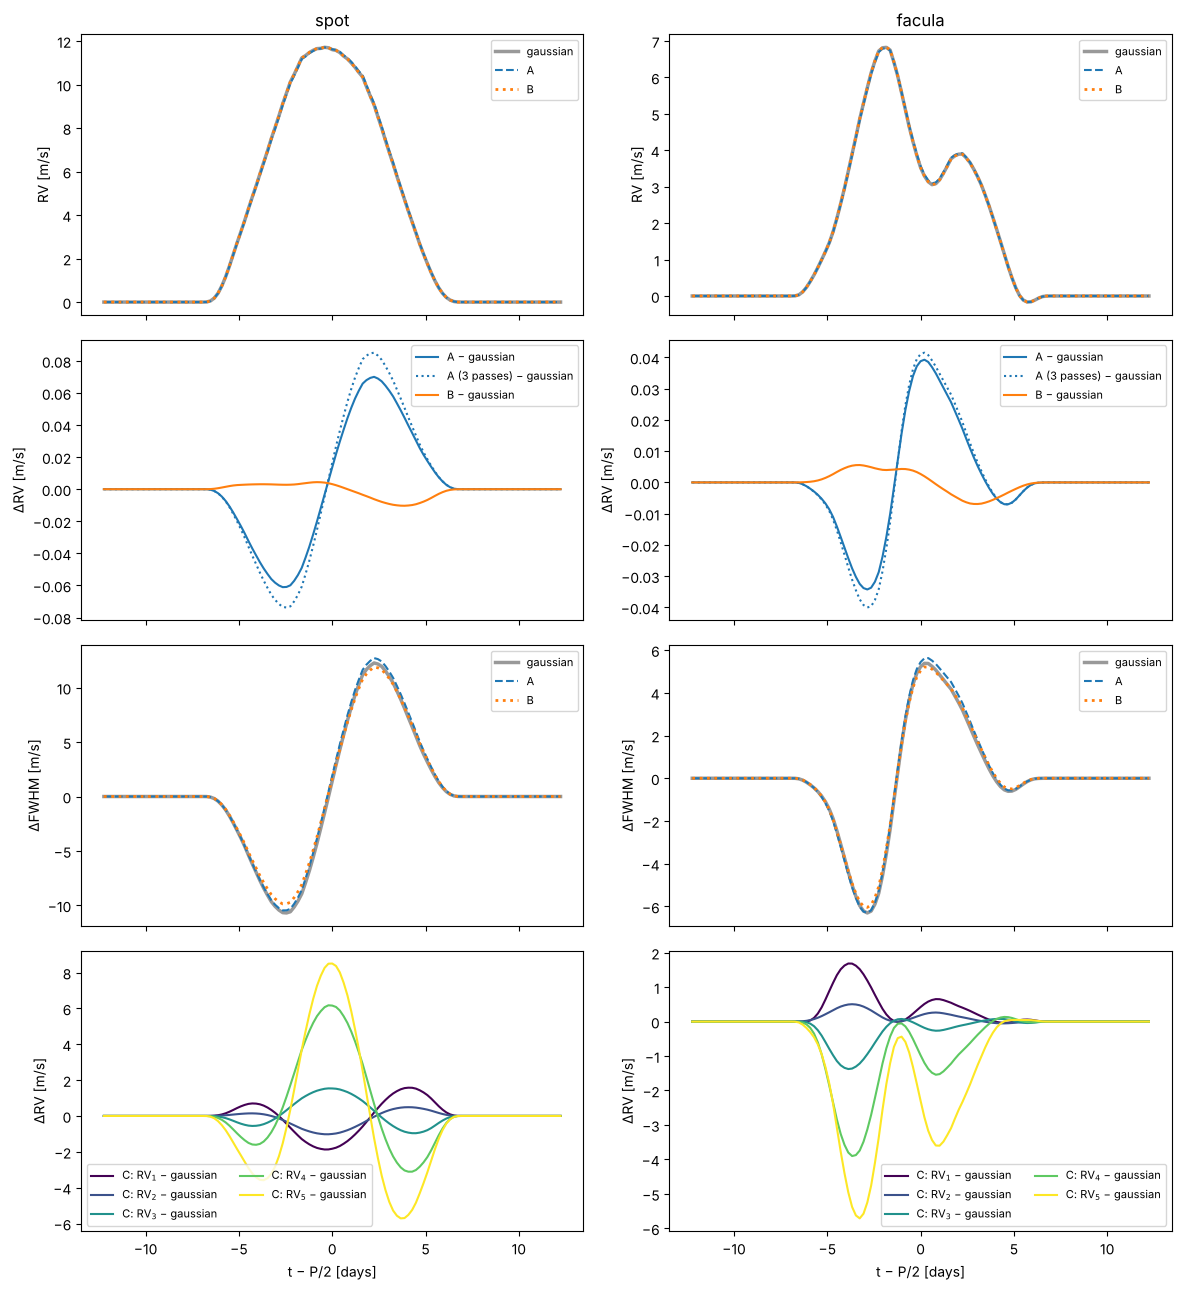

In [9]:
th = time - rotation_period / 2
colors = {'gauss': 'k', 'A': 'C0', 'B': 'C1'}
fig, axes = plt.subplots(4, 2, figsize=(12, 13), sharex=True)
for j, name in enumerate(('spot', 'facula')):
    r = res[name]
    ax = axes[0, j]
    ax.plot(th, r['gauss']['rv'], 'k-', lw=2.5, alpha=0.4, label='gaussian')
    ax.plot(th, r['A']['rv'], 'C0--', label='A')
    ax.plot(th, r['B']['rv'], 'C1:', lw=2, label='B')
    ax.set_ylabel('RV [m/s]'); ax.set_title(name); ax.legend(fontsize=8)

    ax = axes[1, j]
    ax.plot(th, r['A']['rv'] - r['gauss']['rv'], 'C0', label='A − gaussian')
    ax.plot(th, r['A3']['rv'] - r['gauss']['rv'], 'C0:', label='A (3 passes) − gaussian')
    ax.plot(th, r['B']['rv'] - r['gauss']['rv'], 'C1', label='B − gaussian')
    ax.set_ylabel('ΔRV [m/s]'); ax.legend(fontsize=8)

    ax = axes[2, j]
    ax.plot(th, r['gauss']['dfwhm'], 'k-', lw=2.5, alpha=0.4, label='gaussian')
    ax.plot(th, r['A']['dfwhm'], 'C0--', label='A')
    ax.plot(th, r['B']['dfwhm'], 'C1:', lw=2, label='B')
    ax.set_ylabel('ΔFWHM [m/s]'); ax.legend(fontsize=8)

    ax = axes[3, j]
    for k in range(5):
        ax.plot(th, r['F']['rv_k'][:, k] - r['gauss']['rv'], color=plt.cm.viridis(k / 4), label='C: RV$_%d$ − gaussian' % (k + 1))
    ax.set_ylabel('ΔRV [m/s]'); ax.legend(fontsize=8, ncol=2); ax.set_xlabel('t − P/2 [days]')
plt.tight_layout(); plt.show()

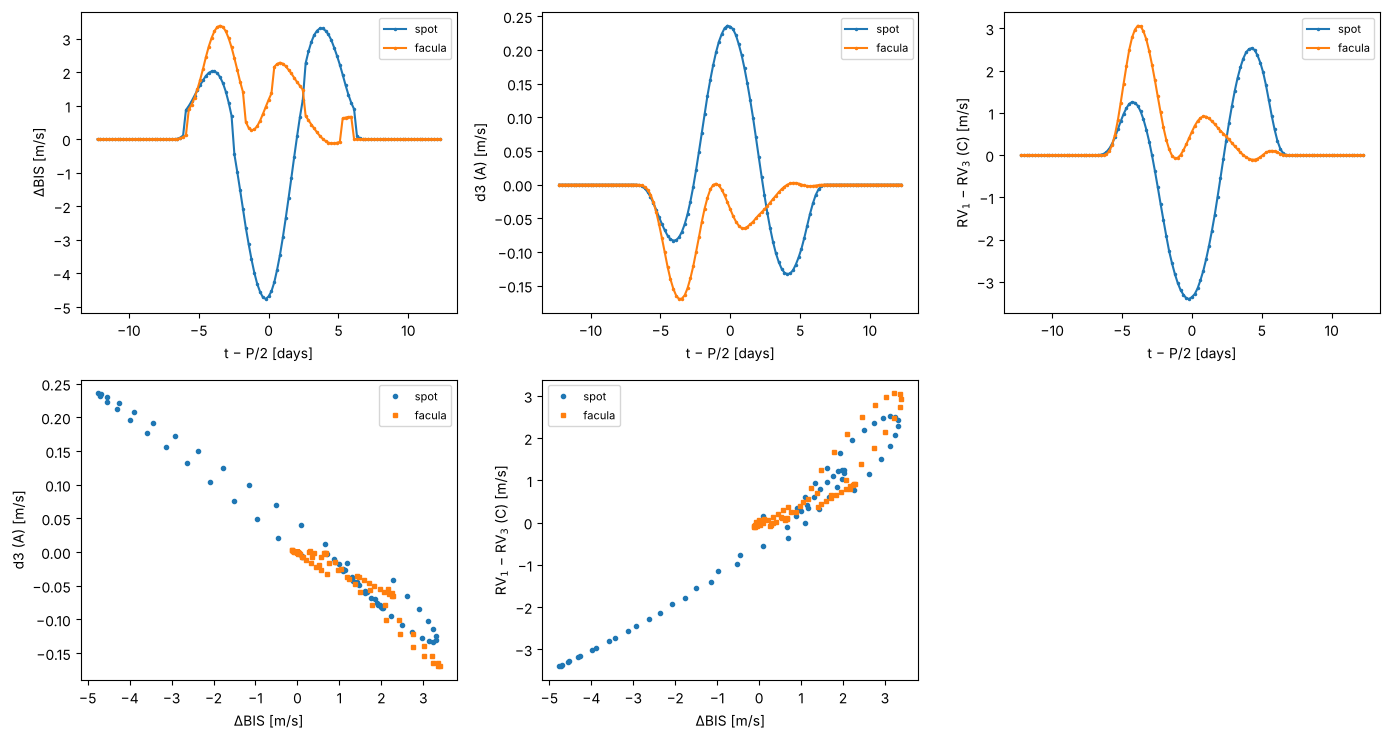

In [10]:
# asymmetry: BIS (gaussian route), d3 (A) and the spread of the FIESTA modes RV_1 - RV_3 (C), against time and against BIS
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for name, mk in (('spot', 'o'), ('facula', 's')):
    r = res[name]
    axes[0, 0].plot(th, r['gauss']['bis'], '.-', ms=3, label=name)
    axes[0, 1].plot(th, r['A']['d3'], '.-', ms=3, label=name)
    axes[0, 2].plot(th, r['F']['rv_k'][:, 0] - r['F']['rv_k'][:, 2], '.-', ms=3, label=name)
    axes[1, 0].plot(r['gauss']['bis'], r['A']['d3'], mk, ms=3, label=name)
    axes[1, 1].plot(r['gauss']['bis'], r['F']['rv_k'][:, 0] - r['F']['rv_k'][:, 2], mk, ms=3, label=name)
for ax, lab in zip(axes[0], ('ΔBIS [m/s]', 'd3 (A) [m/s]', 'RV$_1$ − RV$_3$ (C) [m/s]')):
    ax.set_xlabel('t − P/2 [days]'); ax.set_ylabel(lab); ax.legend(fontsize=8)
axes[1, 0].set_xlabel('ΔBIS [m/s]'); axes[1, 0].set_ylabel('d3 (A) [m/s]'); axes[1, 0].legend(fontsize=8)
axes[1, 1].set_xlabel('ΔBIS [m/s]'); axes[1, 1].set_ylabel('RV$_1$ − RV$_3$ (C) [m/s]'); axes[1, 1].legend(fontsize=8)
axes[1, 2].axis('off')
plt.tight_layout(); plt.show()

In [11]:
def ptp(x):
    return np.max(x) - np.min(x)

for name in ('spot', 'facula'):
    r = res[name]
    g = r['gauss']
    print('\n%s (peak to peak, and rms of the difference with the gaussian route)' % name)
    print('  RV      gaussian %7.3f | A %7.3f (rms diff %.3f) | B %7.3f (rms diff %.3f) | C RV_1..RV_5 %s'
          % (ptp(g['rv']), ptp(r['A']['rv']), np.std(r['A']['rv'] - g['rv']), ptp(r['B']['rv']),
             np.std(r['B']['rv'] - g['rv']), np.round([ptp(r['F']['rv_k'][:, k]) for k in range(5)], 2)))
    print('  dFWHM   gaussian %7.3f | A %7.3f (rms diff %.3f) | B %7.3f (rms diff %.3f)'
          % (ptp(g['dfwhm']), ptp(r['A']['dfwhm']), np.std(r['A']['dfwhm'] - g['dfwhm']), ptp(r['B']['dfwhm']),
             np.std(r['B']['dfwhm'] - g['dfwhm'])))
    print('  contrast (relative) gaussian %.2e | A %.2e | B %.2e' % (ptp(g['con']), ptp(r['A']['a']), ptp(r['B']['a'])))
    print('  asymmetry: BIS %.3f m/s, d3 %.3f m/s; corr(BIS, d3) = %.3f, corr(BIS, RV_1 - RV_3) = %.3f, corr(BIS, A - gaussian) = %.3f'
          % (ptp(g['bis']), ptp(r['A']['d3']), np.corrcoef(g['bis'], r['A']['d3'])[0, 1],
             np.corrcoef(g['bis'], r['F']['rv_k'][:, 0] - r['F']['rv_k'][:, 2])[0, 1],
             np.corrcoef(g['bis'], r['A']['rv'] - g['rv'])[0, 1]))


spot (peak to peak, and rms of the difference with the gaussian route)
  RV      gaussian  11.710 | A  11.707 (rms diff 0.031) | B  11.714 (rms diff 0.004) | C RV_1..RV_5 [ 9.93 10.69 13.23 18.43 21.84]
  dFWHM   gaussian  22.972 | A  23.185 (rms diff 0.193) | B  21.754 (rms diff 0.286)
  contrast (relative) gaussian 2.83e-03 | A 1.39e-03 | B 2.90e-03
  asymmetry: BIS 8.069 m/s, d3 0.369 m/s; corr(BIS, d3) = -0.984, corr(BIS, RV_1 - RV_3) = 0.982, corr(BIS, A - gaussian) = 0.106

facula (peak to peak, and rms of the difference with the gaussian route)
  RV      gaussian   6.990 | A   6.975 (rms diff 0.015) | B   6.995 (rms diff 0.003) | C RV_1..RV_5 [7.4  7.11 6.91 7.04 7.21]
  dFWHM   gaussian  11.681 | A  11.921 (rms diff 0.112) | B  11.256 (rms diff 0.094)
  contrast (relative) gaussian 2.49e-03 | A 2.06e-03 | B 2.51e-03
  asymmetry: BIS 3.510 m/s, d3 0.172 m/s; corr(BIS, d3) = -0.957, corr(BIS, RV_1 - RV_3) = 0.923, corr(BIS, A - gaussian) = -0.179


## 6. Summary

Noise-free simulations; the template comes from the same grids as the CCFs. Numbers from the outputs above.

**Check (section 4).** A recovers shifts to better than 0.01 m/s up to 50 m/s; at 300 m/s a single pass is 0.12 m/s off and 3 passes are exact. B is exact for shifts and stretches. FIESTA modes 1 to 3 are within 0.3 % of the injected shift, modes 4 and 5 are 1 to 2 % off (the CCF is not exactly flat at the edges of the rv grid), which is small compared with the differences between modes in section 5. A gives ΔFWHM about 5 % too large for a stretched template, because its width term is calibrated for a gaussian broadening.

**RV.** For the spot and the facula, A and B give the same RV as the gaussian fit: the rms differences are 0.03 m/s (A) and 0.004 m/s (B) on signals of 12 and 7 m/s, at most 0.08 m/s. For small changes of a nearly gaussian CCF, the gaussian fit is already a projection on (almost) the derivative of the template, so replacing it by the real template changes the RV very little. Here the template does not bring a different RV.

**FWHM and contrast.** A and B follow the gaussian ΔFWHM to within about 5 % (rms differences 0.1 to 0.3 m/s on 12 to 23 m/s).

**Asymmetry: this is where the template methods add something.**
- d3 from A follows BIS closely (correlation −0.98 for the spot, −0.96 for the facula). d3 is smooth, while BIS has kinks: e.g. at the spot egress BIS drops from 0.90 to 0.10 m/s between two epochs while RV only goes from 0.21 to 0.09 m/s. The kinks seem to come from the bisector computation; not investigated here.
- The FIESTA RVs differ from mode to mode by several m/s (up to 8 m/s between RV₅ and the gaussian RV for the spot), with a different pattern for the spot and the facula, so they carry more shape information than one BIS. RV₁ − RV₃ correlates with BIS (0.98 spot, 0.92 facula).

**Cost for 121 CCFs.** A 5 ms and C 6 to 8 ms, about as fast as the current Numba gaussian fit and bisector (10 to 12 ms); B 0.8 s.

**Not tested here:** photon noise (the higher FIESTA modes get noisy first), CCFs far from a gaussian (M dwarfs, fast rotators), where the template RV could differ from the gaussian RV, and observed CCFs, which would need the same treatment with their own template.